# Lesson 18 — Exploratory Data Analysis (EDA) for Quality Engineering

## Manufacturing / Electronics Quality Data

**Goal:** Learn a structured EDA workflow to understand distributions, variability, outliers, relationships, and quality patterns before statistical modeling or ML.

### Learning outcomes
- Build a repeatable EDA workflow
- Analyze distributions with descriptive statistics
- Use histograms, box plots, scatter plots and bar charts
- Detect and investigate outliers
- Analyze correlations correctly
- Compare quality metrics across Line, Shift and Model
- Identify patterns worth investigating with RCA
- Avoid common EDA mistakes in manufacturing data


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')


## 1. Create a realistic manufacturing QA dataset


In [2]:
np.random.seed(42)
n = 300

dates = pd.date_range('2026-09-01', periods=30, freq='D')

df = pd.DataFrame({
    'Date': np.random.choice(dates, n),
    'Line': np.random.choice(['L1', 'L2', 'L3'], n, p=[0.35, 0.40, 0.25]),
    'Shift': np.random.choice(['A', 'B', 'C'], n),
    'Model': np.random.choice(['M1', 'M2', 'M3'], n),
    'Temperature_C': np.random.normal(25, 1.2, n),
    'Pressure_bar': np.random.normal(5.0, 0.25, n),
    'Cycle_Time_sec': np.random.normal(45, 3, n),
    'Inspected': np.random.randint(850, 1150, n)
})

base_rate = 0.018
rate = (
    base_rate
    + np.maximum(df['Temperature_C'] - 26, 0) * 0.008
    + np.maximum(df['Cycle_Time_sec'] - 48, 0) * 0.003
    + (df['Line'] == 'L3') * 0.007
)
rate = np.clip(rate, 0.002, 0.08)

df['Defects'] = np.random.binomial(df['Inspected'], rate)
df['Good'] = df['Inspected'] - df['Defects']
df['Defect_Rate'] = df['Defects'] / df['Inspected'] * 100
df['Yield'] = df['Good'] / df['Inspected'] * 100

df.head()


,Date,Line,Shift,Model,Temperature_C,Pressure_bar,Cycle_Time_sec,Inspected,Defects,Good,Defect_Rate,Yield
0,2026-09-07,L2,A,M3,26.329,5.410,40.501,933,25,908,2.680,97.320
1,2026-09-20,L2,C,M3,25.211,5.375,41.011,1001,17,984,1.698,98.302
2,2026-09-29,L2,A,M2,23.392,5.091,44.963,885,17,868,1.921,98.079
3,2026-09-15,L2,C,M2,25.179,4.605,45.340,1062,20,1042,1.883,98.117
4,2026-09-11,L2,A,M3,23.728,4.857,47.605,955,18,937,1.885,98.115


## 2. First look at the data


In [3]:
df.shape


(300, 12)

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            300 non-null    datetime64[ns]
 1   Line            300 non-null    object        
 2   Shift           300 non-null    object        
 3   Model           300 non-null    object        
 4   Temperature_C   300 non-null    float64       
 5   Pressure_bar    300 non-null    float64       
 6   Cycle_Time_sec  300 non-null    float64       
 7   Inspected       300 non-null    int64         
 8   Defects         300 non-null    int64         
 9   Good            300 non-null    int64         
 10  Defect_Rate     300 non-null    float64       
 11  Yield           300 non-null    float64       
dtypes: datetime64[ns](1), float64(5), int64(3), object(3)
memory usage: 28.3+ KB


In [5]:
df.describe(include='all')


,Date,Line,Shift,Model,Temperature_C,Pressure_bar,Cycle_Time_sec,Inspected,Defects,Good,Defect_Rate,Yield
count,300,300,300,300,300.000,300.000,300.000,300.000,300.000,300.000,300.000,300.000
unique,NaN,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,L2,A,M3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,122,111,102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2026-09-16 01:45:36,NaN,NaN,NaN,25.148,5.030,44.990,996.573,21.960,974.613,2.203,97.797
min,2026-09-01 00:00:00,NaN,NaN,NaN,21.659,4.348,34.945,850.000,8.000,829.000,0.764,93.859
25%,2026-09-08 00:00:00,NaN,NaN,NaN,24.284,4.849,43.182,925.000,17.000,906.500,1.720,97.418
50%,2026-09-16 00:00:00,NaN,NaN,NaN,25.075,5.028,45.120,994.500,21.000,973.500,2.068,97.932
75%,2026-09-25 00:00:00,NaN,NaN,NaN,25.999,5.224,47.060,1065.000,26.000,1043.250,2.582,98.280
max,2026-09-30 00:00:00,NaN,NaN,NaN,28.801,5.776,53.099,1146.000,60.000,1123.000,6.141,99.236


## 3. Data quality checks before EDA


In [6]:
print('Missing values:')
print(df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())


Missing values:
Date              0
Line              0
Shift             0
Model             0
Temperature_C     0
Pressure_bar      0
Cycle_Time_sec    0
Inspected         0
Defects           0
Good              0
Defect_Rate       0
Yield             0
dtype: int64

Duplicate rows: 0


## 4. Descriptive statistics


In [7]:
numeric_cols = [
    'Temperature_C', 'Pressure_bar', 'Cycle_Time_sec',
    'Inspected', 'Defects', 'Defect_Rate', 'Yield']
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Temperature_C,300.000,25.148,1.288,21.659,24.284,25.075,25.999,28.801
Pressure_bar,300.000,5.030,0.267,4.348,4.849,5.028,5.224,5.776
Cycle_Time_sec,300.000,44.990,2.943,34.945,43.182,45.120,47.060,53.099
Inspected,300.000,996.573,82.983,850.000,925.000,994.500,1065.000,1146.000
Defects,300.000,21.960,7.680,8.000,17.000,21.000,26.000,60.000
Defect_Rate,300.000,2.203,0.750,0.764,1.720,2.068,2.582,6.141
Yield,300.000,97.797,0.750,93.859,97.418,97.932,98.280,99.236


### QA interpretation

Look at:
- Mean → central tendency
- Median → robust central tendency
- Std → variation
- Min / Max → possible extreme values
- Quartiles → spread and potential outliers

Do not conclude that a process is good or bad from the mean alone.


In [8]:
df[numeric_cols].agg(['mean', 'median', 'std']).T


,mean,median,std
Temperature_C,25.148,25.075,1.288
Pressure_bar,5.030,5.028,0.267
Cycle_Time_sec,44.990,45.120,2.943
Inspected,996.573,994.500,82.983
Defects,21.960,21.000,7.680
Defect_Rate,2.203,2.068,0.750
Yield,97.797,97.932,0.750


## 5. Distribution of Cycle Time


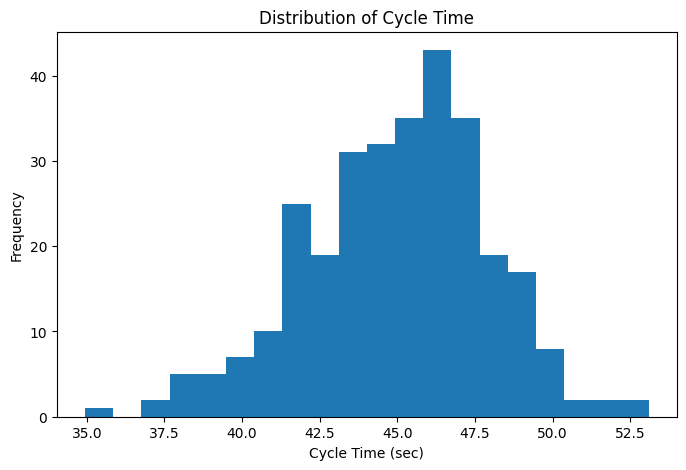

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(df['Cycle_Time_sec'], bins=20)
plt.xlabel('Cycle Time (sec)')
plt.ylabel('Frequency')
plt.title('Distribution of Cycle Time')
plt.show()


## 6. Histogram of Defect Rate


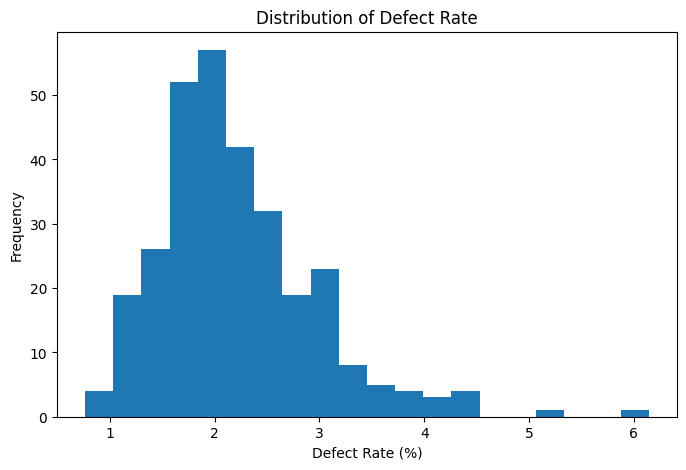

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df['Defect_Rate'], bins=20)
plt.xlabel('Defect Rate (%)')
plt.ylabel('Frequency')
plt.title('Distribution of Defect Rate')
plt.show()


## 7. Box Plot — potential outliers


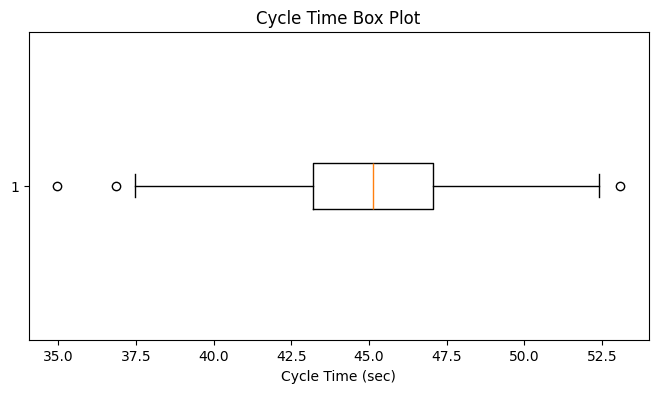

In [11]:
plt.figure(figsize=(8, 4))
plt.boxplot(df['Cycle_Time_sec'].dropna(), vert=False)
plt.xlabel('Cycle Time (sec)')
plt.title('Cycle Time Box Plot')
plt.show()


## 8. IQR method for outlier detection

An IQR outlier is a **screening signal**, not automatic proof of bad data.


In [12]:
q1 = df['Cycle_Time_sec'].quantile(0.25)
q3 = df['Cycle_Time_sec'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print('Q1:', q1)
print('Q3:', q3)
print('IQR:', iqr)
print('Lower limit:', lower)
print('Upper limit:', upper)


Q1: 43.182069670306106
Q3: 47.05998338332643
IQR: 3.8779137130203267
Lower limit: 37.36519910077561
Upper limit: 52.87685395285692


In [13]:
cycle_outliers = df[
    (df['Cycle_Time_sec'] < lower) |
    (df['Cycle_Time_sec'] > upper)
]
cycle_outliers[['Date','Line','Shift','Model','Cycle_Time_sec']].sort_values('Cycle_Time_sec')


,Date,Line,Shift,Model,Cycle_Time_sec
237,2026-09-30,L3,A,M3,34.945
292,2026-09-06,L2,A,M2,36.858
101,2026-09-30,L2,A,M1,53.099


### QA principle

An outlier should be investigated before deletion. Possible causes include measurement error, data-entry error, special cause, equipment issue, setup change, or a genuinely rare process condition.


## 9. Quality summary by Line


In [14]:
line_summary = df.groupby('Line').agg(
    Inspected=('Inspected', 'sum'),
    Defects=('Defects', 'sum'),
    Avg_Cycle_Time=('Cycle_Time_sec', 'mean')
)
line_summary['Defect_Rate'] = line_summary['Defects'] / line_summary['Inspected'] * 100
line_summary['Yield'] = 100 - line_summary['Defect_Rate']
line_summary.round(3)


,Inspected,Defects,Avg_Cycle_Time,Defect_Rate,Yield
Line,,,,,
L1,100799,2039,44.915,2.023,97.977
L2,121091,2449,45.251,2.022,97.978
L3,77082,2100,44.680,2.724,97.276


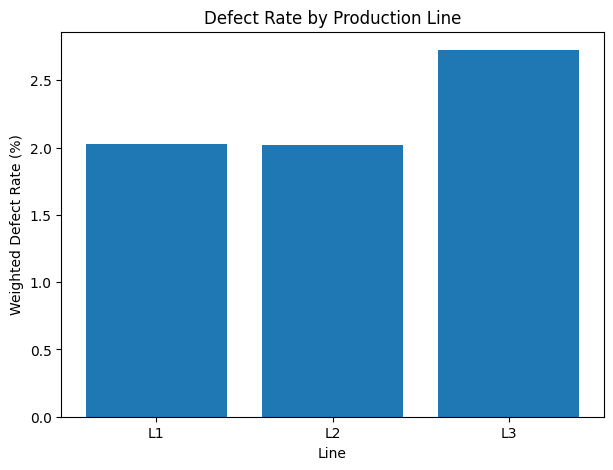

In [15]:
plt.figure(figsize=(7, 5))
plt.bar(line_summary.index, line_summary['Defect_Rate'])
plt.xlabel('Line')
plt.ylabel('Weighted Defect Rate (%)')
plt.title('Defect Rate by Production Line')
plt.show()


## 10. Shift-wise quality analysis


In [16]:
shift_summary = df.groupby('Shift').agg(
    Inspected=('Inspected', 'sum'),
    Defects=('Defects', 'sum'),
    Avg_Cycle_Time=('Cycle_Time_sec', 'mean'))

shift_summary['Defect_Rate'] = shift_summary['Defects'] / shift_summary['Inspected'] * 100
shift_summary['Yield'] = 100 - shift_summary['Defect_Rate']
shift_summary.round(3)


,Inspected,Defects,Avg_Cycle_Time,Defect_Rate,Yield
Shift,,,,,
A,109353,2414,45.274,2.208,97.792
B,97076,2059,44.933,2.121,97.879
C,92543,2115,44.708,2.285,97.715


## 11. Model-wise quality analysis


In [17]:
model_summary = df.groupby('Model').agg(
    Inspected=('Inspected', 'sum'),
    Defects=('Defects', 'sum'),
    Avg_Cycle_Time=('Cycle_Time_sec', 'mean')
)
model_summary['Defect_Rate'] = model_summary['Defects'] / model_summary['Inspected'] * 100
model_summary['Yield'] = 100 - model_summary['Defect_Rate']
model_summary.round(3)


,Inspected,Defects,Avg_Cycle_Time,Defect_Rate,Yield
Model,,,,,
M1,98378,2178,45.155,2.214,97.786
M2,98208,2232,44.703,2.273,97.727
M3,102386,2178,45.110,2.127,97.873


## 12. Line × Shift comparison


In [18]:
line_shift = df.groupby(['Line', 'Shift']).agg(
    Inspected=('Inspected', 'sum'),
    Defects=('Defects', 'sum')
)
line_shift['Defect_Rate'] = line_shift['Defects'] / line_shift['Inspected'] * 100
line_shift['Yield'] = 100 - line_shift['Defect_Rate']
line_shift.round(3)


Inspected  Defects  Defect_Rate  Yield
Line Shift                                        
L1   A          36748      722        1.965 98.035
     B          31894      613        1.922 98.078
     C          32157      704        2.189 97.811
L2   A          40886      841        2.057 97.943
     B          38661      723        1.870 98.130
     C          41544      885        2.130 97.870
L3   A          31719      851        2.683 97.317
     B          26521      723        2.726 97.274
     C          18842      526        2.792 97.208

## 13. Correlation analysis


In [19]:
corr_cols = [
    'Temperature_C', 'Pressure_bar', 'Cycle_Time_sec',
    'Inspected', 'Defects', 'Defect_Rate', 'Yield']

corr = df[corr_cols].corr()
corr.round(2)


,Temperature_C,Pressure_bar,Cycle_Time_sec,Inspected,Defects,Defect_Rate,Yield
Temperature_C,1.000,0.010,-0.080,0.050,0.520,0.530,-0.530
Pressure_bar,0.010,1.000,-0.010,0.040,0.050,0.050,-0.050
Cycle_Time_sec,-0.080,-0.010,1.000,-0.010,0.090,0.090,-0.090
Inspected,0.050,0.040,-0.010,1.000,0.240,0.010,-0.010
Defects,0.520,0.050,0.090,0.240,1.000,0.970,-0.970
Defect_Rate,0.530,0.050,0.090,0.010,0.970,1.000,-1.000
Yield,-0.530,-0.050,-0.090,-0.010,-0.970,-1.000,1.000


### Correlation caution

Correlation measures association, not causation. Also, raw `Defects` is affected by production volume, so `Defect_Rate` can often be a more useful quality metric.


## 14. Temperature vs Defect Rate


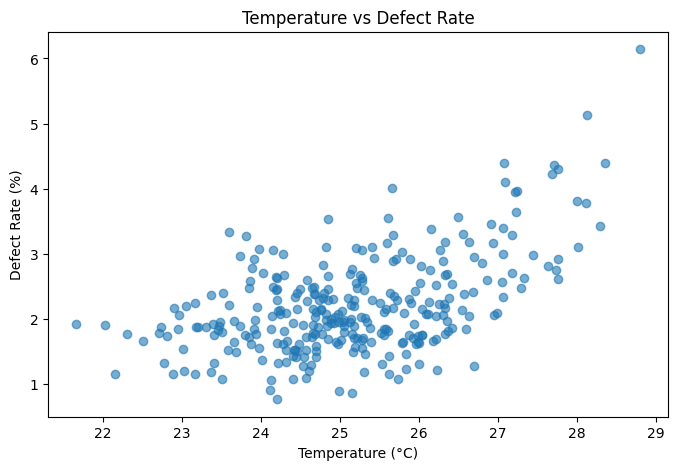

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Temperature_C'], df['Defect_Rate'], alpha=0.6)
plt.xlabel('Temperature (°C)')
plt.ylabel('Defect Rate (%)')
plt.title('Temperature vs Defect Rate')
plt.show()


## 15. Cycle Time vs Defect Rate


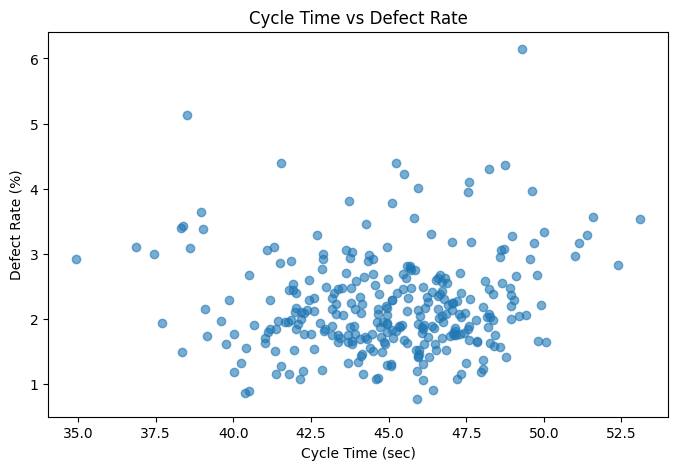

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Cycle_Time_sec'], df['Defect_Rate'], alpha=0.6)
plt.xlabel('Cycle Time (sec)')
plt.ylabel('Defect Rate (%)')
plt.title('Cycle Time vs Defect Rate')
plt.show()


## 16. Grouped process behavior


In [22]:
df.groupby('Line')[['Temperature_C','Pressure_bar','Cycle_Time_sec','Defect_Rate']].mean().round(3)


,Temperature_C,Pressure_bar,Cycle_Time_sec,Defect_Rate
Line,,,,
L1,25.134,5.034,44.915,2.024
L2,25.100,5.035,45.251,2.015
L3,25.243,5.017,44.680,2.727


## 17. Daily quality trend


In [23]:
daily = df.groupby('Date').agg(
    Inspected=('Inspected', 'sum'),
    Defects=('Defects', 'sum'))

daily['Defect_Rate'] = daily['Defects'] / daily['Inspected'] * 100
daily['Yield'] = 100 - daily['Defect_Rate']
daily = daily.sort_index()
daily.head(10).round(3)


,Inspected,Defects,Defect_Rate,Yield
Date,,,,
2026-09-01,11400,237,2.079,97.921
2026-09-02,11168,258,2.310,97.690
2026-09-03,10558,284,2.690,97.310
2026-09-04,8528,204,2.392,97.608
2026-09-05,9086,191,2.102,97.898
2026-09-06,4816,116,2.409,97.591
2026-09-07,14676,391,2.664,97.336
2026-09-08,11555,274,2.371,97.629
2026-09-09,10498,213,2.029,97.971


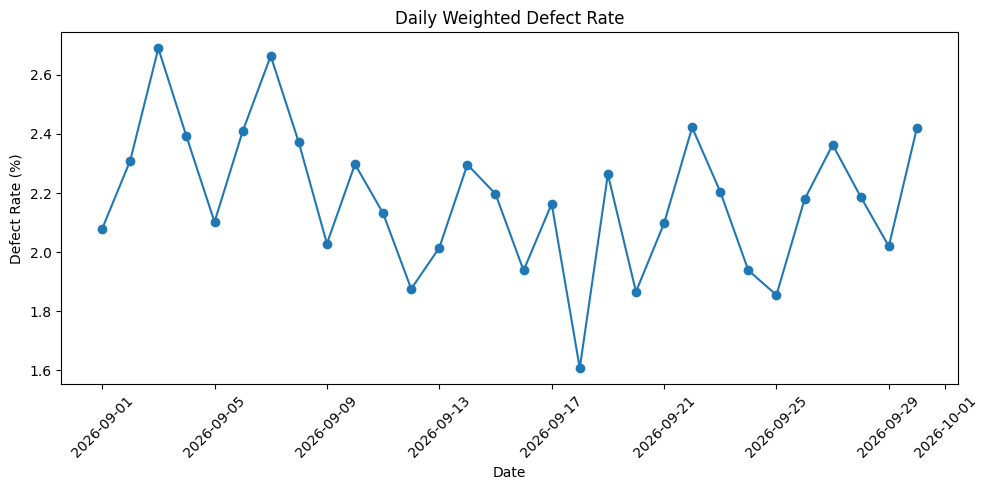

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(daily.index, daily['Defect_Rate'], marker='o')
plt.xlabel('Date')
plt.ylabel('Defect Rate (%)')
plt.title('Daily Weighted Defect Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 18. Pareto-style defect contribution by Line


In [25]:
pareto = df.groupby('Line')['Defects'].sum().sort_values(ascending=False).to_frame()
pareto['Contribution_%'] = pareto['Defects'] / pareto['Defects'].sum() * 100
pareto['Cumulative_%'] = pareto['Contribution_%'].cumsum()
pareto.round(2)


,Defects,Contribution_%,Cumulative_%
Line,,,
L2,2449,37.170,37.170
L3,2100,31.880,69.050
L1,2039,30.950,100.000


## 19. Find observations requiring investigation


In [26]:
investigation = df[
    (df['Defect_Rate'] > df['Defect_Rate'].quantile(0.90)) |
    (df['Cycle_Time_sec'] > df['Cycle_Time_sec'].quantile(0.90))].copy()

investigation[['Date','Line','Shift','Model','Temperature_C','Cycle_Time_sec','Defect_Rate']
].sort_values('Defect_Rate', ascending=False).head(20)


,Date,Line,Shift,Model,Temperature_C,Cycle_Time_sec,Defect_Rate
207,2026-09-07,L3,C,M2,28.801,49.306,6.141
137,2026-09-08,L3,B,M2,28.127,38.514,5.126
229,2026-09-28,L3,B,M2,27.078,45.249,4.397
19,2026-09-03,L3,A,M1,28.355,41.534,4.394
10,2026-09-19,L2,A,M2,27.708,48.747,4.365
113,2026-09-21,L3,A,M1,27.758,48.229,4.297
208,2026-09-27,L3,C,M2,27.683,45.488,4.231
176,2026-09-03,L1,C,M2,27.085,47.581,4.108
231,2026-09-07,L3,B,M2,25.656,45.958,4.004
224,2026-09-30,L3,A,M1,27.238,49.634,3.967


## 20. EDA checklist for Quality Engineers

1. Understand rows, columns and data types.
2. Check missing values, duplicates and invalid values.
3. Study distributions and variability.
4. Screen potential outliers.
5. Segment by Line, Shift, Model, Machine, Operator, Supplier, etc.
6. Study relationships with appropriate plots and correlations.
7. Study time trends.
8. Separate defect counts from defect rates.
9. Generate hypotheses rather than jumping to root cause.
10. Validate important findings with statistical methods.


## 21. Practice Exercises

1. Calculate mean, median and standard deviation for Temperature, Pressure and Cycle Time.
2. Create a histogram of Pressure.
3. Create a box plot for Defect Rate.
4. Use the IQR method to identify Temperature outliers.
5. Calculate weighted defect rate by Model.
6. Compare average Cycle Time across Lines.
7. Create a Line × Shift table of weighted defect rates.
8. Find the correlation between Temperature and Defect Rate.
9. Create a scatter plot of Pressure vs Defect Rate.
10. Find the top 10% highest-defect-rate records and inspect their Line, Shift and Model distribution.


In [ ]:
# Hints
# 1: df[['Temperature_C','Pressure_bar','Cycle_Time_sec']].agg(['mean','median','std']).T
# 2: plt.hist(df['Pressure_bar'], bins=20)
# 3: plt.boxplot(df['Defect_Rate'])
# 4: calculate Q1, Q3 and IQR
# 5: group by Model and divide total defects by total inspected
# 6: df.groupby('Line')['Cycle_Time_sec'].mean()
# 7: group by ['Line','Shift'] and calculate weighted rate
# 8: df['Temperature_C'].corr(df['Defect_Rate'])
# 9: plt.scatter(df['Pressure_bar'], df['Defect_Rate'])
# 10: df.nlargest(int(len(df)*0.10), 'Defect_Rate')


# Mini Project — Quality EDA Report

Prepare an EDA report for a production manager containing:

- Dataset overview
- Missing/duplicate-value check
- Descriptive statistics
- Distribution plots for key process variables
- Outlier investigation
- Line-wise quality comparison
- Shift-wise quality comparison
- Model-wise quality comparison
- Correlation analysis
- At least two process-vs-quality scatter plots
- Daily defect-rate trend
- A short list of observations that deserve RCA

**Important:** EDA should generate questions and hypotheses. It should not be used alone to declare causality.


# Key Takeaways

- EDA is the bridge between raw data and statistical analysis.
- Distribution tells you how a variable behaves.
- Box plots help identify potential outliers.
- IQR is a useful screening method, but engineering context is essential.
- Segmenting by Line, Shift and Model often reveals hidden patterns.
- Correlation is association, not proof of cause.
- Quality counts and quality rates answer different questions.
- Suspicious patterns should be investigated with appropriate statistical methods.

**Next lesson:** Probability fundamentals for Quality Engineers — events, probability rules, conditional probability and manufacturing applications.
